# Logistic Regression — Official Baseline

This notebook reproduces and locks the **official Logistic Regression baseline** used in the thesis.

Run `01_dataset_preparation.ipynb` first in the same runtime so the fixed split and locked TF-IDF objects exist.

Official configuration:

- `LogisticRegression(random_state=42, max_iter=1000)`
- decision threshold: `0.50`
- class `0 = Legitimate`
- class `1 = Phishing`

### Thesis confusion-matrix convention

The project intentionally uses:

- **TP** = legitimate correctly classified as legitimate
- **FP** = legitimate incorrectly classified as phishing
- **FN** = phishing incorrectly classified as legitimate
- **TN** = phishing correctly classified as phishing

Expected official confusion matrix: `[[4660, 88], [48, 5920]]`.


In [ ]:
import os
import json
import hashlib
import joblib
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

EXPECTED_TP = 4660
EXPECTED_FP = 88
EXPECTED_FN = 48
EXPECTED_TN = 5920

EXPECTED_TRAIN_SAMPLES = 42861
EXPECTED_TEST_SAMPLES = 10716
EXPECTED_FEATURES = 10000

OFFICIAL_THRESHOLD = 0.50

EXPECTED_ACCURACY = 0.9873086972751026
EXPECTED_PRECISION = 0.9853528628495339
EXPECTED_RECALL = 0.9919571045576407
EXPECTED_F1 = 0.9886439545758183
EXPECTED_ROC_AUC = 0.9987668012042886

print("Official baseline configuration loaded.")


## 1. Verify prerequisite objects

This notebook deliberately does not recreate the preprocessing pipeline. It expects the exact objects produced by `01_dataset_preparation.ipynb` so that the official split and feature representation remain fixed.


In [ ]:
required_objects = [
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "X_train_tfidf",
    "X_test_tfidf",
    "tfidf_vectorizer"
]

missing = [name for name in required_objects if name not in globals()]

if missing:
    raise RuntimeError(
        "Required objects are missing: "
        + ", ".join(missing)
        + "\nRun 01_dataset_preparation.ipynb first in the same runtime."
    )

assert X_train_tfidf.shape == (EXPECTED_TRAIN_SAMPLES, EXPECTED_FEATURES)
assert X_test_tfidf.shape == (EXPECTED_TEST_SAMPLES, EXPECTED_FEATURES)
assert len(y_train) == EXPECTED_TRAIN_SAMPLES
assert len(y_test) == EXPECTED_TEST_SAMPLES
assert len(tfidf_vectorizer.get_feature_names_out()) == EXPECTED_FEATURES

print("Fixed split and locked TF-IDF representation verified.")


## 2. Train the official Logistic Regression baseline

The model is trained once from the fixed training representation. No class weighting, threshold tuning, feature attenuation, synthetic augmentation, or contextual features are used in the official baseline.


In [ ]:
lr_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

lr_model.fit(X_train_tfidf, y_train)

y_prob = lr_model.predict_proba(X_test_tfidf)[:, 1]
y_pred = (y_prob >= OFFICIAL_THRESHOLD).astype(int)

print("Official Logistic Regression baseline trained.")


## 3. Evaluate and verify the official baseline

Precision, Recall, F1 and ROC-AUC follow scikit-learn's class-1 semantics, where phishing is class 1. The TP/FP/FN/TN labels printed below follow the thesis convention defined above.


In [ ]:
cm = confusion_matrix(y_test, y_pred)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

TP = int(cm[0, 0])
FP = int(cm[0, 1])
FN = int(cm[1, 0])
TN = int(cm[1, 1])

print("Official Baseline Confusion Matrix")
print(cm)

print("\nThesis Convention")
print("TP:", TP)
print("FP:", FP)
print("FN:", FN)
print("TN:", TN)

print("\nOfficial Baseline Metrics")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1       :", f1)
print("ROC-AUC  :", roc_auc)

assert np.array_equal(
    cm,
    np.array([[EXPECTED_TP, EXPECTED_FP],
              [EXPECTED_FN, EXPECTED_TN]])
)

assert np.isclose(accuracy, EXPECTED_ACCURACY, atol=1e-12)
assert np.isclose(precision, EXPECTED_PRECISION, atol=1e-12)
assert np.isclose(recall, EXPECTED_RECALL, atol=1e-12)
assert np.isclose(f1, EXPECTED_F1, atol=1e-12)
assert np.isclose(roc_auc, EXPECTED_ROC_AUC, atol=1e-12)

print("\nOfficial baseline VERIFIED.")


## Baseline figures

The following Python code generates the confusion matrix, error-count chart, and ROC curve from the **verified model predictions**, rather than drawing them from manually entered numbers.

In [ ]:
# Figures are computed from the verified baseline variables above.
# Run this cell in Colab and save notebook outputs for reproducible figures.
import matplotlib.pyplot as plt
from pathlib import Path
FIGURE_DIR = Path("baseline_figures")
FIGURE_DIR.mkdir(exist_ok=True)
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(6.4, 5.1))
im = ax.imshow(cm, cmap="Blues")
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, f"{value:,}", ha="center", va="center",
            fontsize=13, fontweight="bold",
            color="white" if value > cm.max()/2 else "#1d3557")
ax.set_xticks([0, 1], ["Legitimate (0)", "Phishing (1)"])
ax.set_yticks([0, 1], ["Legitimate (0)", "Phishing (1)"])
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_title("Figure 1. Official baseline confusion matrix")
fig.colorbar(im, ax=ax, shrink=.8, label="Email count")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "baseline_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6.4, 4.1))
bars = ax.bar(["False positives", "False negatives"], [FP, FN],
              color=["#2a5b83", "#799fbc"], width=.55)
ax.bar_label(bars, padding=4, fontsize=11)
ax.set_ylim(0, max(FP, FN)*1.2)
ax.set_ylabel("Number of emails")
ax.set_title("Figure 2. Baseline classification errors")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "baseline_error_counts.png", dpi=200, bbox_inches="tight")
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_prob)
fig, ax = plt.subplots(figsize=(6.4, 4.8))
ax.plot(fpr, tpr, linewidth=2, label=f"Logistic Regression (AUC = {roc_auc:.6f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Figure 3. Official baseline ROC curve")
ax.legend(loc="lower right")
ax.grid(alpha=.15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "baseline_roc_curve.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Extract the official False Positive and False Negative cases

These error sets are important inputs to the later explainability and counterfactual stages.

- False Positive: actual legitimate (`0`) predicted phishing (`1`)
- False Negative: actual phishing (`1`) predicted legitimate (`0`)


In [ ]:
test_results = pd.DataFrame({
    "test_index": np.asarray(X_test.index),
    "text": np.asarray(X_test),
    "actual_label": np.asarray(y_test),
    "predicted_label": y_pred,
    "phishing_probability": y_prob
})

false_positives = test_results[
    (test_results["actual_label"] == 0) &
    (test_results["predicted_label"] == 1)
].copy()

false_negatives = test_results[
    (test_results["actual_label"] == 1) &
    (test_results["predicted_label"] == 0)
].copy()

assert len(false_positives) == EXPECTED_FP
assert len(false_negatives) == EXPECTED_FN

print("Locked False Positive cases:", len(false_positives))
print("Locked False Negative cases:", len(false_negatives))


## 5. Save the locked baseline artifacts

For the original Colab experiment, these artifacts were stored in Google Drive under `LR_Official_Baseline_LOCKED`.

The cell below preserves that behavior. It saves the model, vectorizer, predictions, False Positive and False Negative records, configuration/metrics, and SHA-256 integrity hashes.

The vectorizer saved here is the already-fitted training vectorizer. It is **not refitted** in this stage.


In [ ]:
try:
    from google.colab import drive

    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")

    PROJECT_ROOT = (
        "/content/drive/MyDrive/"
        "Logistic_Regression_SHAP_Guided_Phishing_Detection"
    )
except ImportError:
    PROJECT_ROOT = os.path.abspath(
        "Logistic_Regression_SHAP_Guided_Phishing_Detection"
    )

BASELINE_FOLDER = os.path.join(
    PROJECT_ROOT,
    "LR_Official_Baseline_LOCKED"
)
os.makedirs(BASELINE_FOLDER, exist_ok=True)

MODEL_PATH = os.path.join(
    BASELINE_FOLDER, "logistic_regression_baseline.joblib"
)
VECTORIZER_PATH = os.path.join(
    BASELINE_FOLDER, "tfidf_vectorizer_baseline.joblib"
)
PREDICTIONS_PATH = os.path.join(
    BASELINE_FOLDER, "official_baseline_test_predictions.csv"
)
FP_PATH = os.path.join(
    BASELINE_FOLDER, "official_baseline_false_positives.csv"
)
FN_PATH = os.path.join(
    BASELINE_FOLDER, "official_baseline_false_negatives.csv"
)
CONFIG_PATH = os.path.join(
    BASELINE_FOLDER, "official_baseline_metrics_and_config.json"
)
HASH_PATH = os.path.join(
    BASELINE_FOLDER, "baseline_integrity_hashes.json"
)

joblib.dump(lr_model, MODEL_PATH)
joblib.dump(tfidf_vectorizer, VECTORIZER_PATH)

test_results.to_csv(PREDICTIONS_PATH, index=False)
false_positives.to_csv(FP_PATH, index=False)
false_negatives.to_csv(FN_PATH, index=False)

config = {
    "model": "LogisticRegression",
    "random_state": 42,
    "max_iter": 1000,
    "decision_threshold": OFFICIAL_THRESHOLD,
    "train_samples": EXPECTED_TRAIN_SAMPLES,
    "test_samples": EXPECTED_TEST_SAMPLES,
    "tfidf_features": EXPECTED_FEATURES,
    "confusion_matrix": cm.tolist(),
    "thesis_convention": {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN
    },
    "metrics": {
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "roc_auc": float(roc_auc)
    }
}

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Baseline artifacts saved to:")
print(BASELINE_FOLDER)


In [ ]:
def file_sha256(path):
    sha = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(block)
    return sha.hexdigest()

artifact_paths = {
    "model": MODEL_PATH,
    "vectorizer": VECTORIZER_PATH,
    "predictions": PREDICTIONS_PATH,
    "false_positives": FP_PATH,
    "false_negatives": FN_PATH,
    "config": CONFIG_PATH
}

integrity_hashes = {
    name: file_sha256(path)
    for name, path in artifact_paths.items()
}

with open(HASH_PATH, "w", encoding="utf-8") as f:
    json.dump(integrity_hashes, f, indent=2)

print("SHA-256 integrity hashes created.")
for name, value in integrity_hashes.items():
    print(f"{name:16s}: {value}")


## 6. Reload verification

This cell demonstrates the restartable-baseline principle used in the original experiment:

1. load the saved model and vectorizer;
2. reconstruct the matrices with `transform()` only;
3. reproduce the official predictions;
4. verify the exact official confusion matrix.

No baseline retraining and no TF-IDF refitting occur during reload.


In [ ]:
lr_model_reloaded = joblib.load(MODEL_PATH)
tfidf_vectorizer_reloaded = joblib.load(VECTORIZER_PATH)

X_train_tfidf_reloaded = tfidf_vectorizer_reloaded.transform(X_train)
X_test_tfidf_reloaded = tfidf_vectorizer_reloaded.transform(X_test)

y_prob_reloaded = lr_model_reloaded.predict_proba(
    X_test_tfidf_reloaded
)[:, 1]

y_pred_reloaded = (
    y_prob_reloaded >= OFFICIAL_THRESHOLD
).astype(int)

cm_reloaded = confusion_matrix(y_test, y_pred_reloaded)

assert X_train_tfidf_reloaded.shape == (42861, 10000)
assert X_test_tfidf_reloaded.shape == (10716, 10000)
assert np.array_equal(y_pred_reloaded, y_pred)
assert np.allclose(y_prob_reloaded, y_prob)
assert np.array_equal(
    cm_reloaded,
    np.array([[4660, 88], [48, 5920]])
)

for name, path in artifact_paths.items():
    assert file_sha256(path) == integrity_hashes[name]

print("Reload verification PASSED.")
print("No baseline retraining occurred during reload.")
print("Locked TF-IDF vectorizer was not refitted during reload.")


## 7. Objects exposed for later notebooks

For compatibility with the later Logistic Regression analysis, the locked baseline objects remain available under the original names. Aliases used by the counterfactual stages are also provided.


In [ ]:
lr_model = lr_model_reloaded
tfidf_vectorizer = tfidf_vectorizer_reloaded
X_train_tfidf = X_train_tfidf_reloaded
X_test_tfidf = X_test_tfidf_reloaded
y_pred = y_pred_reloaded
y_prob = y_prob_reloaded

feature_names_cf = tfidf_vectorizer.get_feature_names_out()
lr_model_cf = lr_model
tfidf_vectorizer_cf = tfidf_vectorizer

print("=" * 72)
print("RESTARTABLE OFFICIAL LR BASELINE READY")
print("=" * 72)
print(f"TP = {TP} | FP = {FP} | FN = {FN} | TN = {TN}")
print(f"Threshold = {OFFICIAL_THRESHOLD:.2f}")
print("Model loaded:", type(lr_model).__name__)
print("TF-IDF features:", len(feature_names_cf))
print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix :", X_test_tfidf.shape)
print("Locked FP cases:", len(false_positives))
print("Locked FN cases:", len(false_negatives))


### Presentation of the official baseline

The following tables and figures summarize the **previously recorded and locked baseline**. They are embedded for GitHub readability, not represented as newly executed notebook outputs. Running the analysis cells above is still required to independently reproduce and verify the checkpoints.

**Table 1. Official Logistic Regression performance (phishing = positive class for precision, recall and F1).**

| Measure | Recorded value |
|:--|--:|
| Accuracy | 0.987309 |
| Precision (phishing) | 0.985353 |
| Recall (phishing) | 0.991957 |
| F1-score (phishing) | 0.988644 |
| ROC-AUC | 0.998767 |

**Table 2. Official confusion matrix (rows: actual, columns: predicted).**

| Actual class | Predicted legitimate (0) | Predicted phishing (1) |
|:--|--:|--:|
| Legitimate (0) | 4,660 | 88 |
| Phishing (1) | 48 | 5,920 |

*The 88 legitimate emails incorrectly predicted as phishing are false positives; the 48 phishing emails incorrectly predicted as legitimate are false negatives. In this project's custom thesis convention, the diagonal entries are called TP = 4,660 and TN = 5,920. This differs from the standard class-1-positive interpretation used by scikit-learn.*

**Table 3. Error counts for subsequent explainability analysis.**

| Error type | Cases | Percentage of test set |
|:--|--:|--:|
| False positives | 88 | 0.821% |
| False negatives | 48 | 0.448% |
| Total misclassifications | 136 | 1.269% |


**Figure 1. Recorded baseline confusion matrix (reference visualization).**

This embedded figure is generated from the previously recorded matrix `[[4660, 88], [48, 5920]]`; it is **not** evidence that the notebook was rerun. The executable plotting cell above produces a fresh figure from the verified predictions.

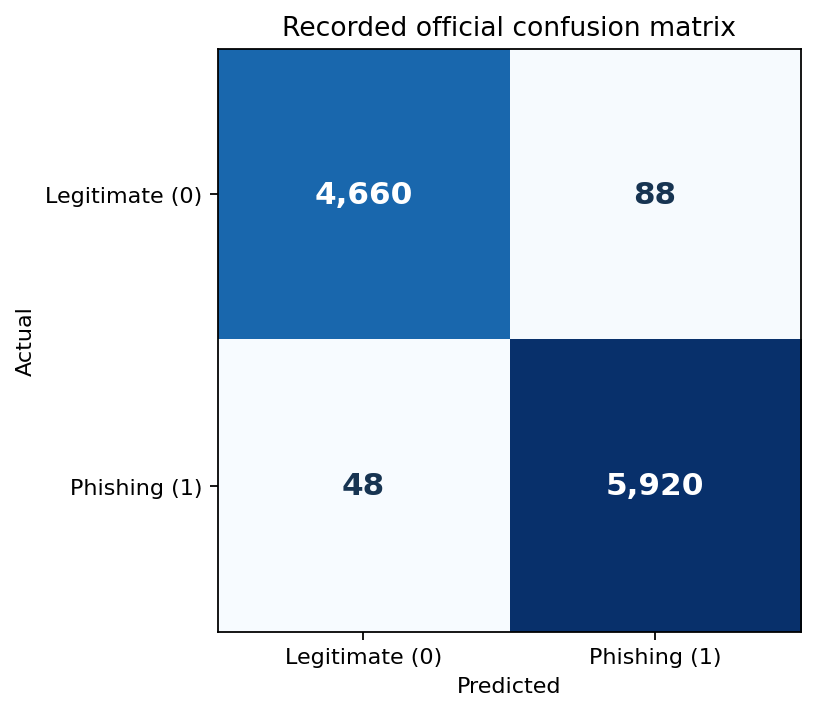

**Figure 2. Recorded baseline classification errors (reference visualization).**  
The counts (88 false positives and 48 false negatives) are from the locked baseline. This embedded figure does not establish that the notebook was rerun.

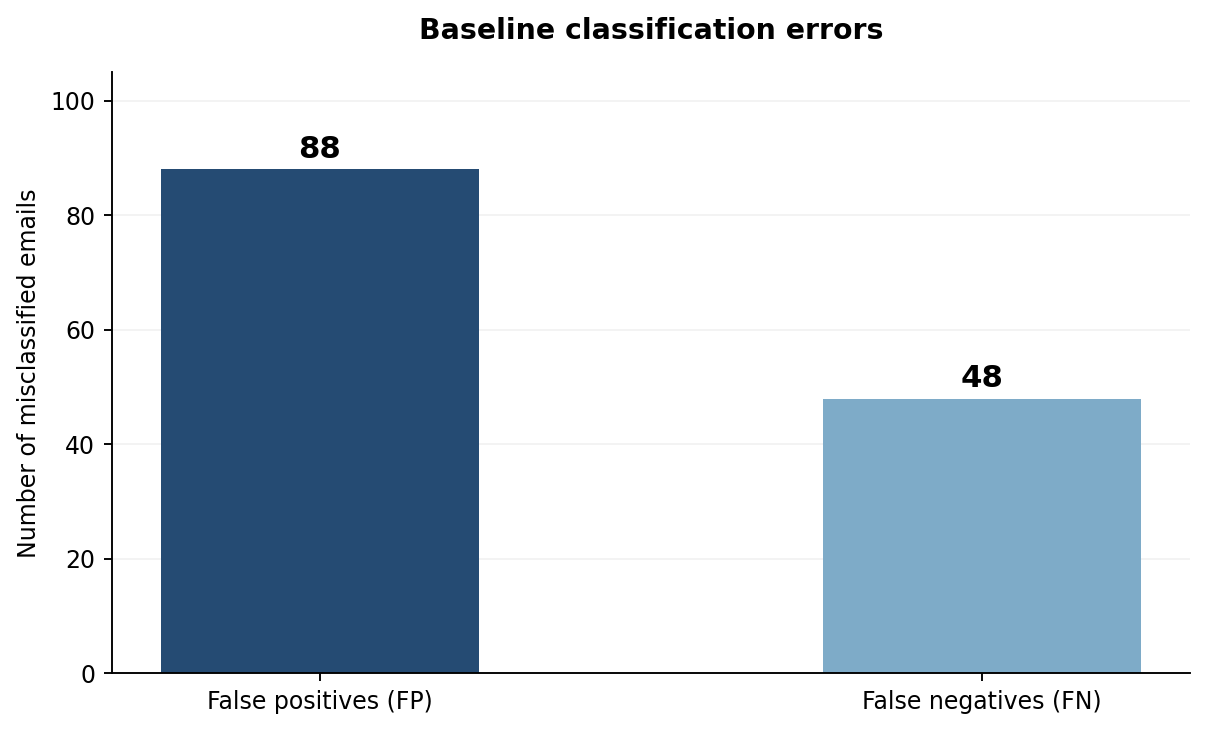

**Figure 3. ROC curve — generated from model predictions.**

The ROC plotting code above calculates the curve from `y_test` and `y_prob` and reports the verified AUC. **The exact curve cannot be reconstructed from AUC alone.** Run the figure-generation cell in Colab and save the notebook with outputs to display the genuine ROC figure here on GitHub.

## Official baseline checkpoint

The notebook must finish with:

| Metric | Official value |
|---|---:|
| TP | 4,660 |
| FP | 88 |
| FN | 48 |
| TN | 5,920 |
| Accuracy | 0.9873086972751026 |
| Precision | 0.9853528628495339 |
| Recall | 0.9919571045576407 |
| F1 | 0.9886439545758183 |
| ROC-AUC | 0.9987668012042886 |

This baseline is the fixed reference for all subsequent Logistic Regression refinement experiments.
